# Who gets the carbon dividend?

Name: Meinardas Grinius

**Recommendation for the finance minister**

**Pay the dividend by location and household need: the equal dividend leaves 24 of 39 low-income rural households out of pocket**

The equal dividend (EUR 575) is fair by income on average, but not by location or household size. Rural households use more heating and travel fuel. Table 1 shows that 24 of the 39 low-income rural households pay more than they receive. I recommend EUR 419 for every household, EUR 209 more if rural, and EUR 209 or EUR 105 more if income is low for the household size. Low-income net payers fall from 32 to 16 of 93. The 101 urban households above the limit carry the cost: their mean result goes from a gain of EUR 16 to a cost of EUR 127. Figure 1 shows the limit of the rule: the spread inside each group stays wide, and 9 low-income rural households still pay. With one limit and one step of EUR 210 the result is 14, so the recommendation holds.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

h = pd.read_csv(Path("households.csv"))
h["tax"] = 100 * (h["heat_t"] + h["travel_t"])
revenue = h["tax"].sum()
h["equal_dividend"] = revenue / len(h)
h["net_equal"] = h["tax"] - h["equal_dividend"]
print(f"{len(h)} households | Revenue EUR {revenue:,.2f} | Equal dividend EUR {revenue / len(h):,.2f}")
print("Equal-rule unallocated revenue (EUR):", round(revenue - h["equal_dividend"].sum(), 6))
assert abs(revenue - h["equal_dividend"].sum()) < 0.01

240 households | Revenue EUR 137,916.00 | Equal dividend EUR 574.65
Equal-rule unallocated revenue (EUR): 0.0


### Your economic priority and policy rule
**Priority.** No low-income household should pay for the policy because of where it lives or how many persons it has. The equal dividend already helps low incomes on average. The losses that remain are in rural households and in large households, which use more heating and travel fuel.

**Rule a household can check.** Every household gets EUR 419. A rural household gets EUR 209 more. A household with low income for its size gets one income addition: EUR 209 or EUR 105, not the two together. The household finds its line in this table and reads the one column that contains its annual income:

| Persons in household | Addition of EUR 209: income up to | Addition of EUR 105: income from, to | No addition: income above |
|---|---|---|---|
| 1 | EUR 22,000 | EUR 22,001 to EUR 26,000 | EUR 26,000 |
| 2 | EUR 30,000 | EUR 30,001 to EUR 34,000 | EUR 34,000 |
| 3 | EUR 38,000 | EUR 38,001 to EUR 42,000 | EUR 42,000 |
| 4 | EUR 46,000 | EUR 46,001 to EUR 50,000 | EUR 50,000 |
| 5 | EUR 54,000 | EUR 54,001 to EUR 58,000 | EUR 58,000 |

Example: a rural household of 3 persons with an income of EUR 40,000 gets EUR 419 + EUR 209 + EUR 105 = EUR 733.

**How the amounts are calculated.** The income limit is EUR 24,000 for one person plus EUR 8,000 for each additional person. The two levels are EUR 2,000 below and EUR 2,000 above this limit. Each household gets 1 point, plus 0.5 point if rural, plus 0.5 point (first level) or 0.25 point (second level) for low income. Revenue divided by total points gives the value of one point. Thus the full revenue goes back to households.

**Why the rule is permitted.** Income, household size and residence are pre-policy characteristics. Emissions and the tax bill do not enter the rule, and all households face the same EUR 100 per tonne.

In [7]:
# Optional helper for rules expressed as nonnegative household weights.
# Example: passing a Series of ones reproduces the equal household dividend.
def distribute(weights):
    weights = pd.Series(weights, index=h.index, dtype=float)
    assert np.isfinite(weights).all() and (weights >= 0).all() and weights.sum() > 0
    return revenue * weights / weights.sum()

FIRST, EXTRA, BAND = 24_000, 8_000, 2_000   # EUR: limit for one person, for each additional person, half-width of the two levels

h["rural"] = h["area"].eq("Rural")
h["limit"] = FIRST + EXTRA * (h["people"] - 1)          # income limit for the household size
h["low"] = h["income_eur"] <= h["limit"]                # low income for household size
h["rural_points"] = 0.5 * h["rural"]

def income_points(band):
    """0.5 point up to (limit - band), 0.25 point up to (limit + band), 0 above. band=0 gives one limit."""
    return np.where(h["income_eur"] <= h["limit"] - band, 0.5,
                    np.where(h["income_eur"] <= h["limit"] + band, 0.25, 0.0))

h["points"] = 1 + h["rural_points"] + income_points(BAND)
h["proposal"] = distribute(h["points"])
h["net_prop"] = h["tax"] - h["proposal"]

# Net cost as a percentage of the household's own income (positive = pays more than it receives)
h["pct_equal"] = 100 * h["net_equal"] / h["income_eur"]
h["pct_prop"] = 100 * h["net_prop"] / h["income_eur"]

point = revenue / h["points"].sum()
print(f"One point = EUR {point:,.2f} | rural addition EUR {point / 2:,.2f} | income addition EUR {point / 2:,.2f} or EUR {point / 4:,.2f}")
print(f"Households at or below the limit for their size: {h['low'].sum()} of {len(h)} ({h['low'].mean():.0%})")
print(h.groupby("points")["proposal"].agg(households="size", dividend_eur="first").round(2))

One point = EUR 418.56 | rural addition EUR 209.28 | income addition EUR 209.28 or EUR 104.64
Households at or below the limit for their size: 93 of 240 (39%)
        households  dividend_eur
points                          
1.00            88        418.56
1.25            22        523.20
1.50            85        627.84
1.75            14        732.48
2.00            31        837.12


In [3]:
print("Equal rule, unallocated revenue (EUR):      ", round(revenue - h["equal_dividend"].sum(), 6))
print("Recommended rule, unallocated revenue (EUR):", round(revenue - h["proposal"].sum(), 6))
assert h["proposal"].notna().all() and (h["proposal"] >= 0).all()
assert abs(h["proposal"].sum() - revenue) < 0.01
assert abs(h["net_equal"].sum()) < 0.01 and abs(h["net_prop"].sum()) < 0.01   # net costs sum to zero

Equal rule, unallocated revenue (EUR):       0.0
Recommended rule, unallocated revenue (EUR): 0.0


### Table
**Table 1. Who pays and who gains: equal dividend against the recommended rule, by income group and residence.**
"Low income" means income at or below the limit for the household size (EUR 24,000 plus EUR 8,000 for each additional person). Net cost = tax minus dividend, per household per year. A positive value means that the household pays more than it receives. The percentage is the mean of each household's net cost divided by its own income. "Net payers" is the number of households with a positive net cost.

In [4]:
h["group"] = np.where(h["low"], "Low income for size", "Higher income") + ", " + h["area"].str.lower()
order = ["Low income for size, rural", "Low income for size, urban", "Higher income, rural", "Higher income, urban"]

def summary(d):
    return pd.Series({
        ("Households", "number"): len(d),
        ("Mean dividend, EUR", "Equal"): d["equal_dividend"].mean(),
        ("Mean dividend, EUR", "Recommended"): d["proposal"].mean(),
        ("Mean net cost, EUR", "Equal"): d["net_equal"].mean(),
        ("Mean net cost, EUR", "Recommended"): d["net_prop"].mean(),
        ("Mean net cost, % of income", "Equal"): d["pct_equal"].mean(),
        ("Mean net cost, % of income", "Recommended"): d["pct_prop"].mean(),
        ("Net payers, households", "Equal"): (d["net_equal"] > 0).sum(),
        ("Net payers, households", "Recommended"): (d["net_prop"] > 0).sum(),
    })

table = pd.DataFrame({g: summary(h[h["group"] == g]) for g in order} | {"All households": summary(h)}).T
table.columns = pd.MultiIndex.from_tuples(table.columns)
whole = [col for col in table.columns if "%" not in col[0]]
table[whole] = table[whole].round(0).astype(int)
pct_cols = [col for col in table.columns if "%" in col[0]]
table.style.format("{:+.2f}", subset=pct_cols).format("{:+,d}", subset=[col for col in whole if "net cost" in col[0]])

### Figure
**Figure 1. The recommended rule moves low-income rural households from net payers to net gainers, and higher-income urban households pay for it.**
Each dot is one household. Each group has two rows: the equal dividend (orange) and the recommended rule (blue). Dots to the right of the zero line pay more than they receive. The table shows group means. The figure shows the spread inside each group: households in the same group have very different results, and some low-income households still pay under the two rules.

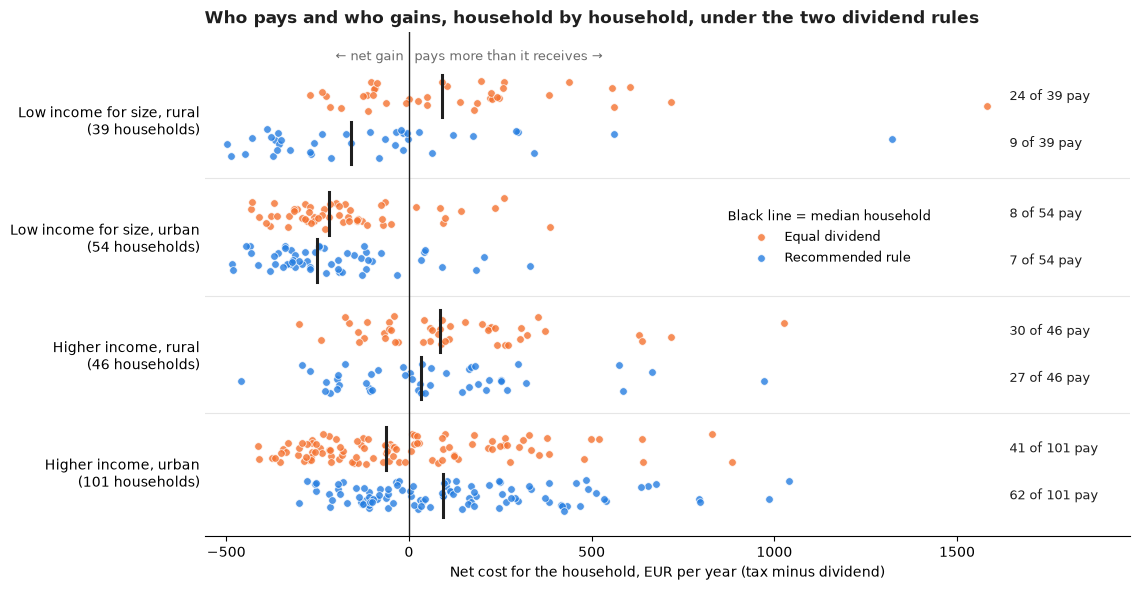

Low-income rural households: median net cost EUR +89 (equal), EUR -158 (recommended). Largest net cost under the recommended rule: EUR 1,321.


In [5]:
ORANGE, BLUE, INK, MUTED = "#f47230", "#257de0", "#1f1f1f", "#6b6b6b"
rng = np.random.default_rng(1)                      # fixed seed: the vertical jitter is reproducible
rules = [("net_equal", "Equal dividend", ORANGE, 0.2), ("net_prop", "Recommended rule", BLUE, -0.2)]
x_text = h[["net_equal", "net_prop"]].max().max() + 60

fig, ax = plt.subplots(figsize=(11.5, 6))
for i, g in enumerate(order):
    d = h[h["group"] == g]
    y0 = len(order) - 1 - i
    for col, name, colour, off in rules:
        y = y0 + off + rng.uniform(-0.13, 0.13, len(d))
        ax.scatter(d[col], y, s=30, color=colour, alpha=0.8, edgecolor="white", linewidth=0.6,
                   label=name if i == 0 else None)
        ax.plot([d[col].median()] * 2, [y0 + off - 0.18, y0 + off + 0.18], color=INK, linewidth=2.2)
        ax.text(x_text, y0 + off, f"{(d[col] > 0).sum()} of {len(d)} pay", va="center", fontsize=9.5, color=INK)
    if i:
        ax.axhline(y0 + 0.5, color="#e6e6e6", linewidth=0.8)

ax.axvline(0, color=INK, linewidth=1)
ax.set_yticks(range(len(order)))
ax.set_yticklabels([f"{g}\n({(h['group'] == g).sum()} households)" for g in order[::-1]])
ax.set_xlim(h[["net_equal", "net_prop"]].min().min() - 60, x_text + 330)
ax.set_xlabel("Net cost for the household, EUR per year (tax minus dividend)")
ax.text(15, len(order) - 0.52, "pays more than it receives →", fontsize=9, color=MUTED, va="bottom")
ax.text(-15, len(order) - 0.52, "← net gain", fontsize=9, color=MUTED, va="bottom", ha="right")
ax.set_ylim(-0.55, len(order) - 0.25)
ax.tick_params(axis="y", length=0)
for side in ["top", "right", "left"]:
    ax.spines[side].set_visible(False)
ax.legend(loc="center", bbox_to_anchor=(1150, 2.0), bbox_transform=ax.transData, frameon=False, fontsize=9.5,
          title="Black line = median household", title_fontsize=9)
ax.set_title("Who pays and who gains, household by household, under the two dividend rules",
             loc="left", fontsize=12.5, fontweight="bold", color=INK)
fig.tight_layout()
plt.show()

lr = h[h["group"] == order[0]]
print(f"Low-income rural households: median net cost EUR {lr['net_equal'].median():+,.0f} (equal), "
      f"EUR {lr['net_prop'].median():+,.0f} (recommended). Largest net cost under the recommended rule: EUR {lr['net_prop'].max():,.0f}.")

### Challenge and AI check
**Challenge.** I replaced the two levels with one limit: EUR 209 more at or below the limit for the household size, and nothing above it. Low-income net payers are 32 of 93 under the equal dividend, 16 under the recommended rule and 14 under the one-limit rule. The recommendation survives. The one-limit rule is simpler and a little better on this count, but its step is EUR 210 and not EUR 105. I also changed the test to "households that lose more than 1% of income": 14 under the equal dividend and 12 under the two versions. A flat limit of EUR 34,200 for all household sizes gives 24, so the limit by household size is the important part of the rule.

**Limits.** The data are for one year with fixed quantities. If households cut emissions, revenue and dividends fall. This is a hypothesis and it is not tested here. The amounts for household size (EUR 24,000 and EUR 8,000) are a judgment.

**AI check.** Claude suggested an equal amount per person as a rival rule; I ran it in the cell below and it helped large low-income households (18 to 3 net payers of 27), but low-income net payers did not decrease (32 to 33) and households that lose more than 1% of income increased from 14 to 22, so I rejected it and used household size only in the income limit.

In [6]:
# Judge all rules on the same fixed groups.
large_low = h["low"] & (h["people"] >= 4)

def check(label, dividend, step):
    net = h["tax"] - dividend
    assert (dividend >= 0).all() and abs(dividend.sum() - revenue) < 0.01
    return {"Rule": label,
            f"Low-income net payers (of {h['low'].sum()})": int((net[h["low"]] > 0).sum()),
            f"Large low-income net payers, 4+ persons (of {large_low.sum()})": int((net[large_low] > 0).sum()),
            "Lose more than 1% of income (of 240)": int((100 * net / h["income_eur"] > 1).sum()),
            "All net payers (of 240)": int((net > 0).sum()),
            "Largest step at an income limit, EUR": round(step)}

one_limit_points = 1 + h["rural_points"] + income_points(0)
flat_points = 1 + h["rural_points"] + 0.5 * (h["income_eur"] <= 34_200)
challenge = pd.DataFrame([
    check("Equal dividend", h["equal_dividend"], 0),
    check("Recommended: two levels by household size", h["proposal"], point / 4),
    check("Challenge: one limit by household size", distribute(one_limit_points), revenue / one_limit_points.sum() / 2),
    check("Flat limit EUR 34,200 for all sizes", distribute(flat_points), revenue / flat_points.sum() / 2),
    check("AI suggestion: equal amount per person", distribute(h["people"]), 0),
]).set_index("Rule")
challenge

,Low-income net payers (of 93),"Large low-income net payers, 4+ persons (of 27)",Lose more than 1% of income (of 240),All net payers (of 240),"Largest step at an income limit, EUR"
Rule,,,,,
Equal dividend,32,18,14,103,0
Recommended: two levels by household size,16,11,12,105,105
Challenge: one limit by household size,14,10,12,106,210
"Flat limit EUR 34,200 for all sizes",24,19,13,109,209
AI suggestion: equal amount per person,33,3,22,112,0
